# 2.0 - Sinal no futuro e recomendacao de ajustes

1. Existe sinal das tags em instantes no futuro? (AP, sem depender de limiar)
2. O ganho das tags e real ou acaso? (teste de permutacao)
3. Quem vem antes: a tag ou a pluma? (lead-lag)
4. Recomendacao de ajustes nas tags para baixar o risco de pluma
5. A recomendacao se sustenta em outro periodo? (validacao)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ml_atmospheric_emission.config import PROJ_ROOT, TAGS, CALENDARIO, FEATURES, VARIAVEIS_CONTROLE
from ml_atmospheric_emission.dataset import load_interim
from ml_atmospheric_emission.features import create_datetime_columns, create_target, create_future_targets
from ml_atmospheric_emission.modeling.train import create_model
from ml_atmospheric_emission.modeling.evaluate import split_holdout, signal_by_horizon, permutation_test_tags, lead_lag, lead_lag_null
from ml_atmospheric_emission.modeling.recommend import create_limits, create_support, recommend_actions, print_recommendation, validate_recommendations

In [3]:
qtd_deslocamento = 24   #24 x 5 min = 2 horas no futuro
ds = load_interim()
ds = create_datetime_columns(ds)
ds = create_target(ds)
dx = create_future_targets(ds, qtd_deslocamento)

#The hold out (last 20% of the period) is separated ONCE and is not used in this notebook
dx_treino, dx_holdout = split_holdout(dx)

Treino ate: 2026-10-02 13:40:00 | linhas treino: 12059 | linhas hold out: 3015


## 1. Existe sinal no futuro?

AP (average precision) no CV temporal, sem usar o hold out.
Comparamos o modelo **tags + calendario** com o modelo **so calendario**:
a hora do dia sozinha ja explica muito (a camera so ve a pluma de dia).
O que importa e o ganho das tags acima do calendario.

In [4]:
tabela_sinal = signal_by_horizon(dx_treino, TAGS, CALENDARIO, qtd_deslocamento)

 minutos  prevalencia  ap_calendario  ap_tags  ganho_tags  folds_tags_vence
       0        0.086          0.165    0.162      -0.003                 3
       5        0.086          0.163    0.178       0.014                 3
      10        0.086          0.160    0.187       0.028                 4
      15        0.086          0.164    0.165       0.001                 3
      20        0.086          0.163    0.168       0.004                 3
      25        0.086          0.161    0.183       0.023                 3
      30        0.086          0.164    0.177       0.014                 3
      35        0.086          0.160    0.182       0.023                 4
      40        0.086          0.162    0.188       0.026                 4
      45        0.086          0.164    0.180       0.016                 4
      50        0.086          0.163    0.192       0.029                 4
      55        0.086          0.164    0.186       0.023                 4
      60    

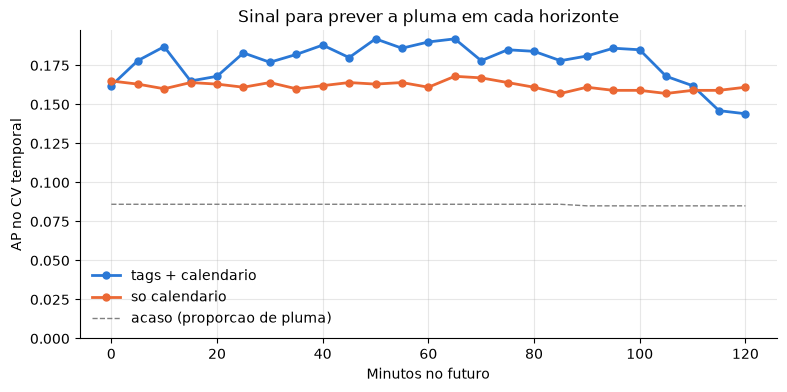

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabela_sinal['minutos'], tabela_sinal['ap_tags'], color='#2a78d6', linewidth=2, marker='o', markersize=5, label='tags + calendario')
ax.plot(tabela_sinal['minutos'], tabela_sinal['ap_calendario'], color='#eb6834', linewidth=2, marker='o', markersize=5, label='so calendario')
ax.plot(tabela_sinal['minutos'], tabela_sinal['prevalencia'], color='gray', linewidth=1, linestyle='--', label='acaso (proporcao de pluma)')
ax.set_title('Sinal para prever a pluma em cada horizonte')
ax.set_xlabel('Minutos no futuro')
ax.set_ylabel('AP no CV temporal')
ax.set_ylim(0, None)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False)
fig.savefig(PROJ_ROOT / 'reports/figures/sinal_por_horizonte.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. O ganho das tags e real ou acaso?

Embaralhamos os dias: cada dia recebe as tags de outro dia, no mesmo horario, e retreinamos.
As tags continuam com o mesmo comportamento (inclusive o padrao do dia), mas perdem a ligacao com a pluma. Se o ganho real for maior que quase
todos os ganhos "de acaso", o sinal e real. Um teste so, para todos os horizontes de 15 a 120 min.
Demora alguns minutos.

In [6]:
resultado_perm = permutation_test_tags(dx_treino, TAGS, CALENDARIO, [3, 6, 9, 12, 15, 18, 21, 24], n_perm=100)

{'minutos': [15, 30, 45, 60, 75, 90, 105, 120], 'ganho_real': np.float64(0.0117), 'ganho_acaso_medio': np.float64(0.0025), 'ganho_acaso_p95': np.float64(0.0268), 'p_valor': 0.257}


## 3. Quem vem antes: a tag ou a pluma?

Correlacao de Spearman entre a tag agora e o score daqui a X minutos, sem o efeito da hora.
Minutos positivos: a tag vem antes (pode ser aviso ou causa). Negativos: vem depois (consequencia).

In [7]:
tabela_lead_lag = lead_lag(dx_treino, TAGS, [-120, -60, -30, 0, 30, 60, 120])
limites_acaso = lead_lag_null(dx_treino, TAGS)

                   -120   -60    -30     0      30     60     120
306-AIT-004-2    -0.081 -0.094 -0.095 -0.092 -0.100 -0.095 -0.081
306-AIT-004-5    -0.062 -0.078 -0.080 -0.072 -0.078 -0.072 -0.050
306FE002-AI001-R  0.070  0.038  0.033  0.022  0.002 -0.006  0.001
406-AI-004-2      0.058  0.049  0.045  0.044  0.052  0.055  0.063
406-AI-004-4     -0.045 -0.051 -0.053 -0.042 -0.034 -0.020 -0.000
406-AIT-001       0.102  0.102  0.086  0.087  0.091  0.085  0.066


Correlacao maxima esperada por acaso (95%): {'306-AIT-004-2': np.float64(0.089), '306-AIT-004-5': np.float64(0.084), '306FE002-AI001-R': np.float64(0.103), '406-AI-004-2': np.float64(0.096), '406-AI-004-4': np.float64(0.122), '406-AIT-001': np.float64(0.084)}


## 4. Recomendacao (horizonte de 60 minutos)

So o periodo de treino (o hold out fica guardado), dividido em duas metades com um intervalo entre elas.
Cada metade treina um modelo. `class_weight=None` para o risco ficar perto da chance real.

In [8]:
deslocamento_ = 12   #12 x 5 min = 60 minutos
target = 'y_60'
dr = dx_treino[dx_treino[target].notna()].sort_values('Data').reset_index(drop=True)
dr['classe'] = (dr[target] >= 0.5).astype(int)

#Two periods with a gap between them
meio = len(dr) // 2
periodo_1 = dr.iloc[:meio - deslocamento_].reset_index(drop=True)
periodo_2 = dr.iloc[meio:].reset_index(drop=True)
print('Periodo 1:', periodo_1['Data'].min(), 'ate', periodo_1['Data'].max())
print('Periodo 2:', periodo_2['Data'].min(), 'ate', periodo_2['Data'].max())

model_1 = create_model(class_weight=None)
model_1.fit(periodo_1[FEATURES], periodo_1['classe'])
model_2 = create_model(class_weight=None)
model_2.fit(periodo_2[FEATURES], periodo_2['classe'])

Periodo 1: 2026-08-20 14:15:00 ate 2026-09-11 08:30:00
Periodo 2: 2026-09-11 09:35:00 ate 2026-10-02 12:35:00


,num_leaves,15
,max_depth,4
,learning_rate,0.05
,n_estimators,200
,min_child_samples,100
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,reg_lambda,1.0
,random_state,42
,verbose,-1


In [9]:
#Examples: recommendations of model 1 for the 3 moments of highest risk in period 2
limites = create_limits(periodo_1, VARIAVEIS_CONTROLE)
suporte = create_support(periodo_1, VARIAVEIS_CONTROLE)
risco = model_1.predict_proba(periodo_2[FEATURES])[:, 1]
for i in np.argsort(-risco)[:3]:
    linha = periodo_2.iloc[i]
    recomendacao = recommend_actions(model_1, linha, FEATURES, VARIAVEIS_CONTROLE, limites, suporte)
    print_recommendation(linha['Data'], recomendacao)

Momento: 2026-09-25 09:00:00
Risco de pluma previsto agora: 0.816
Risco com a recomendacao: 0.458
  baixar 306-AIT-004-2 de 66.611 para 50.632
  subir 306-AIT-004-5 de 220.131 para 228.189
  baixar 306FE002-AI001-R de 5.809 para 4.75
  subir 406-AI-004-2 de 27.315 para 37.301
  subir 406-AI-004-4 de 130.471 para 135.467
  baixar 406-AIT-001 de 1.593 para 1.224

Momento: 2026-09-25 08:55:00
Risco de pluma previsto agora: 0.807
Risco com a recomendacao: 0.153
  baixar 306-AIT-004-2 de 67.157 para 51.178
  subir 306-AIT-004-5 de 218.979 para 227.037
  baixar 306FE002-AI001-R de 7.566 para 4.92
  subir 406-AI-004-2 de 43.772 para 50.262
  baixar 406-AI-004-4 de 155.969 para 134.794
  baixar 406-AIT-001 de 2.205 para 1.836

Momento: 2026-09-25 12:25:00
Risco de pluma previsto agora: 0.777
Risco com a recomendacao: 0.382
  baixar 306-AIT-004-2 de 97.2 para 87.613
  subir 306-AIT-004-5 de 276.827 para 317.117
  baixar 406-AI-004-2 de 107.028 para 98.763
  baixar 406-AI-004-4 de 305.318 para 2

## 5. A recomendacao se sustenta em outro periodo?

O modelo de um periodo recomenda nos momentos de alto risco do seu periodo; o modelo do OUTRO periodo
(que nunca viu esses momentos) confere. Controle: fazer o contrario da recomendacao (mesmo tamanho).
Se a recomendacao for real, o outro modelo tambem ve o risco cair, e fazer o contrario nao ajuda.

In [10]:
print('Recomenda: modelo do periodo 1 | Confere: modelo do periodo 2')
tabela_1, direcoes_1 = validate_recommendations(model_1, model_2, periodo_1, FEATURES, VARIAVEIS_CONTROLE)
print('Recomenda: modelo do periodo 2 | Confere: modelo do periodo 1')
tabela_2, direcoes_2 = validate_recommendations(model_2, model_1, periodo_2, FEATURES, VARIAVEIS_CONTROLE)

Recomenda: modelo do periodo 1 | Confere: modelo do periodo 2


Momentos avaliados: 150
Reducao de risco segundo o modelo que recomendou: 0.296
Reducao de risco segundo o modelo do outro periodo: 0.027
Reducao fazendo o contrario (outro periodo): -0.056
Outro periodo concorda que o risco cai: 55 %
Recomendacao melhor que fazer o contrario: 59 %
Direcoes recomendadas:
406-AIT-001 baixar         112
406-AI-004-2 subir         101
406-AI-004-4 baixar         95
306FE002-AI001-R baixar     95
306-AIT-004-2 subir         75
306-AIT-004-2 baixar        64
306-AIT-004-5 baixar        64
406-AI-004-4 subir          48
306-AIT-004-5 subir         47
406-AI-004-2 baixar         37
306FE002-AI001-R subir      35
406-AIT-001 subir           15

Recomenda: modelo do periodo 2 | Confere: modelo do periodo 1


Momentos avaliados: 150
Reducao de risco segundo o modelo que recomendou: 0.504
Reducao de risco segundo o modelo do outro periodo: -0.006
Reducao fazendo o contrario (outro periodo): 0.013
Outro periodo concorda que o risco cai: 58 %
Recomendacao melhor que fazer o contrario: 37 %
Direcoes recomendadas:
306-AIT-004-2 subir        118
306FE002-AI001-R subir     102
406-AI-004-4 subir          82
406-AI-004-2 baixar         79
406-AIT-001 baixar          73
306-AIT-004-5 subir         70
306-AIT-004-5 baixar        65
406-AI-004-2 subir          59
406-AI-004-4 baixar         58
406-AIT-001 subir           53
306FE002-AI001-R baixar     39
306-AIT-004-2 baixar        21



In [11]:
#Same direction in both periods? If not, the recommendation is not stable
ds_direcoes = pd.DataFrame({'periodo_1': direcoes_1, 'periodo_2': direcoes_2}).fillna(0).astype(int)
ds_direcoes.sort_index()

,periodo_1,periodo_2
306-AIT-004-2 baixar,64,21
306-AIT-004-2 subir,75,118
306-AIT-004-5 baixar,64,65
306-AIT-004-5 subir,47,70
306FE002-AI001-R baixar,95,39
306FE002-AI001-R subir,35,102
406-AI-004-2 baixar,37,79
406-AI-004-2 subir,101,59
406-AI-004-4 baixar,95,58
406-AI-004-4 subir,48,82
